
Libries


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_curve, auc
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from scipy.sparse import hstack

Dataset

In [ ]:
from google.colab import files
up = files.upload()

Saving fake_job_postings.csv to fake_job_postings.csv


EDA


In [ ]:
data= pd.read_csv("fake_job_postings.csv")
print("Data size:", data.shape)
data.head()

Data size: (17880, 18)


,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent
0,1,Marketing Intern,"US, NY, New York",Marketing,NaN,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,NaN,0,1,0,Other,Internship,NaN,NaN,Marketing,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,NaN,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,NaN,Marketing and Advertising,Customer Service,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",NaN,NaN,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,NaN,0,1,0,NaN,NaN,NaN,NaN,NaN,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,NaN,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0
4,5,Bill Review Manager,"US, FL, Fort Worth",NaN,NaN,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17880 entries, 0 to 17879
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   job_id               17880 non-null  int64 
 1   title                17880 non-null  object
 2   location             17534 non-null  object
 3   department           6333 non-null   object
 4   salary_range         2868 non-null   object
 5   company_profile      14572 non-null  object
 6   description          17879 non-null  object
 7   requirements         15184 non-null  object
 8   benefits             10668 non-null  object
 9   telecommuting        17880 non-null  int64 
 10  has_company_logo     17880 non-null  int64 
 11  has_questions        17880 non-null  int64 
 12  employment_type      14409 non-null  object
 13  required_experience  10830 non-null  object
 14  required_education   9775 non-null   object
 15  industry             12977 non-null  object
 16  func

In [ ]:
data.describe(include="all").transpose()

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
job_id,17880.0,NaN,NaN,NaN,8940.5,5161.655742,1.0,4470.75,8940.5,13410.25,17880.0
title,17880,11231,English Teacher Abroad,311,NaN,NaN,NaN,NaN,NaN,NaN,NaN
location,17534,3105,"GB, LND, London",718,NaN,NaN,NaN,NaN,NaN,NaN,NaN
department,6333,1337,Sales,551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salary_range,2868,874,0-0,142,NaN,NaN,NaN,NaN,NaN,NaN,NaN
company_profile,14572,1709,We help teachers get safe &amp; secure jobs ab...,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
description,17879,14801,"Play with kids, get paid for it Love travel? J...",379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
requirements,15184,11967,University degree required. TEFL / TESOL / CEL...,410,NaN,NaN,NaN,NaN,NaN,NaN,NaN
benefits,10668,6204,See job description,726,NaN,NaN,NaN,NaN,NaN,NaN,NaN
telecommuting,17880.0,NaN,NaN,NaN,0.042897,0.202631,0.0,0.0,0.0,0.0,1.0


In [ ]:
var = data.columns[data.dtypes=="object"]
print(var)

Index(['title', 'location', 'department', 'salary_range', 'company_profile',
       'description', 'requirements', 'benefits', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function'],
      dtype='object')


In [ ]:
miss_val = data.isnull().sum()
print("Value Missing:\n", miss_val)

Value Missing:
 job_id                     0
title                      0
location                 346
department             11547
salary_range           15012
company_profile         3308
description                1
requirements            2696
benefits                7212
telecommuting              0
has_company_logo           0
has_questions              0
employment_type         3471
required_experience     7050
required_education      8105
industry                4903
function                6455
fraudulent                 0
dtype: int64


Missing Value Heatmap

Missing Values:
 salary_range           15012
department             11547
required_education      8105
benefits                7212
required_experience     7050
function                6455
industry                4903
employment_type         3471
company_profile         3308
requirements            2696
location                 346
description                1
title                      0
job_id                     0
telecommuting              0
has_questions              0
has_company_logo           0
fraudulent                 0
dtype: int64


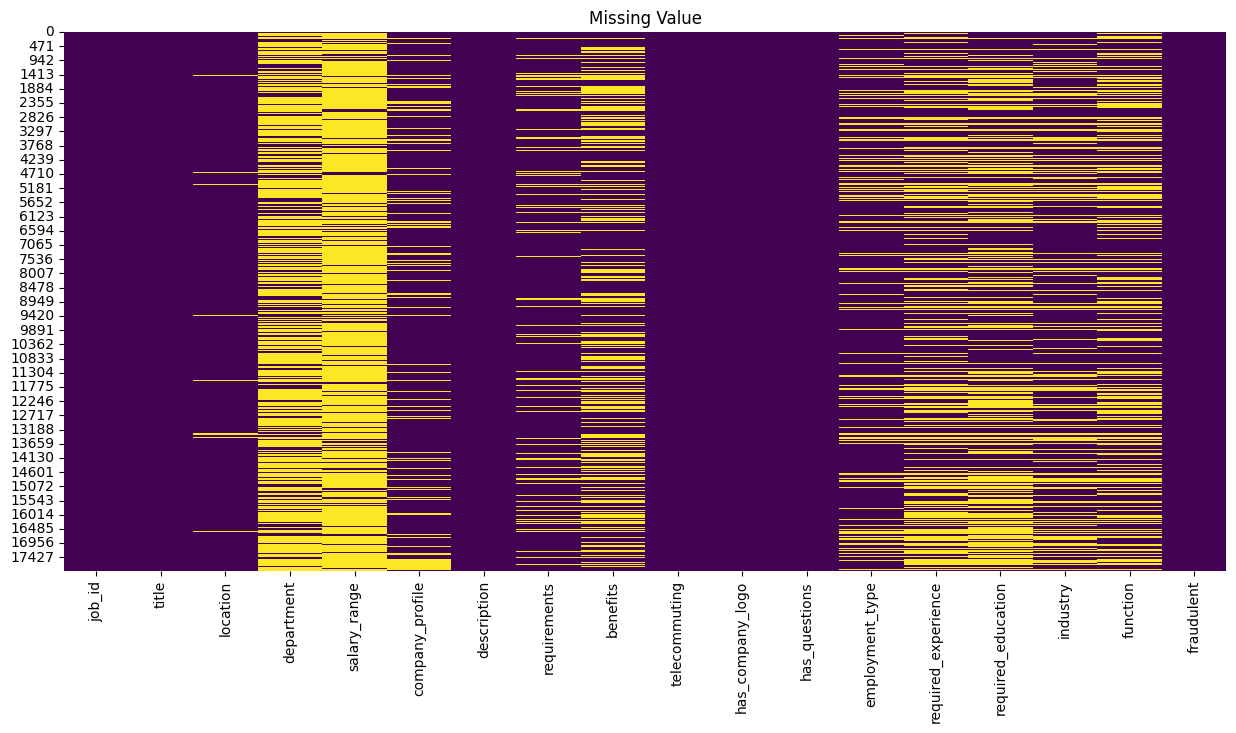

In [ ]:
miss= data.isnull().sum().sort_values(ascending=False)
print("Missing Values:\n",miss.head(25))
plt.figure(figsize=(15,7))
sns.heatmap(data.isnull(), cbar=False, cmap="viridis")
plt.title("Missing Value")
plt.show()


Handle Missing Values

In [ ]:
data = pd.read_csv("fake_job_postings.csv")
data = data.fillna("")
print("After fill null remain:\n",  data.isnull().sum())

After fill null remain:
 job_id                 0
title                  0
location               0
department             0
salary_range           0
company_profile        0
description            0
requirements           0
benefits               0
telecommuting          0
has_company_logo       0
has_questions          0
employment_type        0
required_experience    0
required_education     0
industry               0
function               0
fraudulent             0
dtype: int64


Heatmap after handle missing values:
 Axes(0.125,0.11;0.62x0.77)


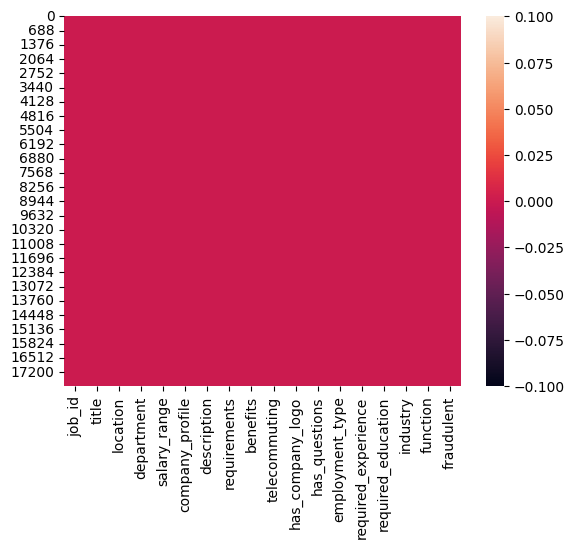

In [ ]:
print("Heatmap after handle missing values:\n", sns.heatmap(data.isnull()))

In [ ]:
data["job_type"] = data["fraudulent"].map({0: "Real", 1: "Fraud"})
data.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,job_type
0,1,Marketing Intern,"US, NY, New York",Marketing,,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,,0,1,0,Other,Internship,,,Marketing,0,Real
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,,Marketing and Advertising,Customer Service,0,Real
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",,,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,,0,1,0,,,,,,0,Real
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,Real
4,5,Bill Review Manager,"US, FL, Fort Worth",,,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,Real


In [ ]:
data['fraudulent'].value_counts()

,count
fraudulent,
0,17014
1,866


In [ ]:
data.columns

Index(['job_id', 'title', 'location', 'department', 'salary_range',
       'company_profile', 'description', 'requirements', 'benefits',
       'telecommuting', 'has_company_logo', 'has_questions', 'employment_type',
       'required_experience', 'required_education', 'industry', 'function',
       'fraudulent', 'job_type'],
      dtype='object')

In [ ]:
job = data[data["fraudulent"]==1]
fake= job.title.value_counts().head(20)
print(fake)

title
Data Entry Admin/Clerical Positions - Work From Home                    21
Cruise Staff Wanted *URGENT*                                            21
Home Based Payroll Typist/Data Entry Clerks Positions Available         21
Customer Service Representative                                         17
Administrative Assistant                                                16
Home Based Payroll Data Entry Clerk Position - Earn $100-$200 Daily     12
Account Sales Managers $80-$130,000/yr                                  10
Payroll Data Coordinator Positions - Earn $100-$200 Daily               10
Network Marketing                                                       10
Payroll Clerk                                                           10
Agency Sales Managers $150-$175,000/yr                                   9
Data Entry                                                               9
Lawn and Maintenance Contractors                                         6
Call Center Represe

In [ ]:
data[data.fraudulent==0].title.value_counts()[:20]

,count
title,
English Teacher Abroad,311
Customer Service Associate,146
Graduates: English Teacher Abroad (Conversational),144
English Teacher Abroad,95
Software Engineer,86
English Teacher Abroad (Conversational),83
Customer Service Associate - Part Time,76
Account Manager,73
Web Developer,66


,0
job_type,
Fraud,866
Real,17014


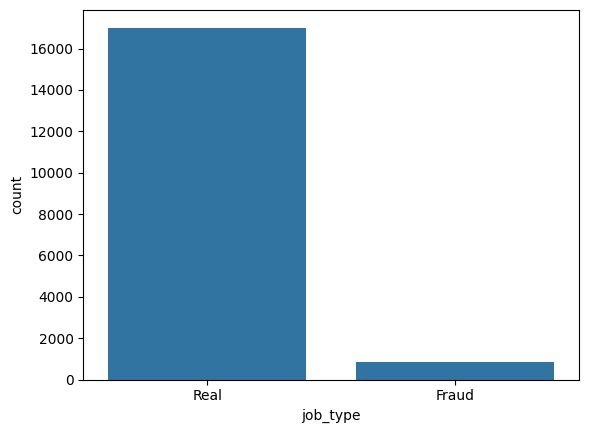

In [ ]:
sns.countplot(x="job_type",data=data)
data.groupby("job_type").size()

 TEXT Features


In [ ]:
data["text"] = data["title"] + " " + data["description"] + " " + data["requirements"]

In [ ]:
data.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,has_company_logo,has_questions,employment_type,required_experience,required_education,industry,function,fraudulent,job_type,text
0,1,Marketing Intern,"US, NY, New York",Marketing,,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,,0,1,0,Other,Internship,,,Marketing,0,Real,"Marketing Intern Food52, a fast-growing, James..."
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,1,0,Full-time,Not Applicable,,Marketing and Advertising,Customer Service,0,Real,Customer Service - Cloud Video Production Orga...
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",,,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,,0,1,0,,,,,,0,Real,Commissioning Machinery Assistant (CMA) Our cl...
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,1,0,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,Real,Account Executive - Washington DC THE COMPANY:...
4,5,Bill Review Manager,"US, FL, Fort Worth",,,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,1,1,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,Real,Bill Review Manager JOB TITLE: Itemization Rev...


Metadata Features

In [ ]:
def available(value):

    if value == "":
        return 0

    return 1


data["has_company"] = data["company_profile"].apply(available)

data["has_salary"] = data["salary_range"].apply(available)

In [ ]:
data.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,...,employment_type,required_experience,required_education,industry,function,fraudulent,job_type,text,has_company,has_salary
0,1,Marketing Intern,"US, NY, New York",Marketing,,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,,0,...,Other,Internship,,,Marketing,0,Real,"Marketing Intern Food52, a fast-growing, James...",1,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,...,Full-time,Not Applicable,,Marketing and Advertising,Customer Service,0,Real,Customer Service - Cloud Video Production Orga...,1,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",,,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,,0,...,,,,,,0,Real,Commissioning Machinery Assistant (CMA) Our cl...,1,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,...,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,Real,Account Executive - Washington DC THE COMPANY:...,1,0
4,5,Bill Review Manager,"US, FL, Fort Worth",,,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,...,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,Real,Bill Review Manager JOB TITLE: Itemization Rev...,1,0


In [ ]:
import re

def clean(s):

    s = s.lower()

    s = re.sub(r"[^a-z0-9 ]", " ",s)

    return s


data["text"] = data["text"].apply(clean)


In [ ]:
data.head()

,job_id,title,location,department,salary_range,company_profile,description,requirements,benefits,telecommuting,...,employment_type,required_experience,required_education,industry,function,fraudulent,job_type,text,has_company,has_salary
0,1,Marketing Intern,"US, NY, New York",Marketing,,"We're Food52, and we've created a groundbreaki...","Food52, a fast-growing, James Beard Award-winn...",Experience with content management systems a m...,,0,...,Other,Internship,,,Marketing,0,Real,marketing intern food52 a fast growing james...,1,0
1,2,Customer Service - Cloud Video Production,"NZ, , Auckland",Success,,"90 Seconds, the worlds Cloud Video Production ...",Organised - Focused - Vibrant - Awesome!Do you...,What we expect from you:Your key responsibilit...,What you will get from usThrough being part of...,0,...,Full-time,Not Applicable,,Marketing and Advertising,Customer Service,0,Real,customer service cloud video production orga...,1,0
2,3,Commissioning Machinery Assistant (CMA),"US, IA, Wever",,,Valor Services provides Workforce Solutions th...,"Our client, located in Houston, is actively se...",Implement pre-commissioning and commissioning ...,,0,...,,,,,,0,Real,commissioning machinery assistant cma our cl...,1,0
3,4,Account Executive - Washington DC,"US, DC, Washington",Sales,,Our passion for improving quality of life thro...,THE COMPANY: ESRI – Environmental Systems Rese...,"EDUCATION: Bachelor’s or Master’s in GIS, busi...",Our culture is anything but corporate—we have ...,0,...,Full-time,Mid-Senior level,Bachelor's Degree,Computer Software,Sales,0,Real,account executive washington dc the company ...,1,0
4,5,Bill Review Manager,"US, FL, Fort Worth",,,SpotSource Solutions LLC is a Global Human Cap...,JOB TITLE: Itemization Review ManagerLOCATION:...,QUALIFICATIONS:RN license in the State of Texa...,Full Benefits Offered,0,...,Full-time,Mid-Senior level,Bachelor's Degree,Hospital & Health Care,Health Care Provider,0,Real,bill review manager job title itemization rev...,1,0


In [ ]:
data.groupby("company_profile")["description"].sum()

,description
company_profile,
,Job OverviewApex is an environmental consultin...
"Value Added Team of Creative ProfessionalsNetConstructor is a San Diego based company Co-Founded by Christian Hochfilzer, Leo Baghdassarian and Kris Fredrickson and is composed of a tightly-knit group of talented and experienced professionals in the realm of marketing and media development. At the heart of NetConstructor is the simple belief that results speak for themselves. We understand that regardless of how aesthetically pleasing an advertisement or website may be, or how much theoretical sense the technique makes, unless the campaign produces the desired results, it has failed.Our Mission:At NetConstructor, we pride ourselves in utilizing technology to develop innovative ROI-focused marketing and media solutions that help our clients embrace the constantly evolving business place. We aim to build and nurture mutually beneficial partnerships with our clients and take an immense amount of pride in the work we perform and campaigns we launch on behalf of each and every company with which we work.Our Process:Our process is simple. By combining tried-and-true principles of advertising and human behavior, we plan each project with your target market in mind. We take a uniquely human approach to everything that we do and are constantly asking “how might the consumer react to this?” At the end of the day, we measure success by results. As such, we maintain an acute focus on how what we’re doing will have an impact where it counts: your bottom line.",Why Work for NetConstructor:Join NetConstructo...
"""Only stupid questions create wealth"" - Gary HamelA successful business needs stupid questions and great design.We do both.We, are the Fooolish Designers.",We are looking for a skilled web designer / fr...
"""Our mission to our clients is to preserve their independence, enhance their quality of life, promote health &amp; wellbeing and have them consider us a part of their family.""",We are currently seeking a Client Care Advocat...
"""Play anything on your TV at anytime with the tap of a finger"" - sounds like a lazy man's ambition, doesn't it? Teewe is one device which we believe can achieve this goal. Teewe is an HDMI Dongle, which allows you to stream media wirelessly via a smartphone application to your television. Get the device home, plug it into your TV's HDMI, download the app and you are good to go!Teewe is Mango Man Consumer Electronics Pvt. Ltd's flagship product. At Mango Man we are obsessed about making great electronic products that are extremely affordable. We believe that a connected home entertainment experience is the next step in the smart life evolution and we aim to be at the forefront of it.Find more about us at #URL_5fc03a7a10c772c41d82945eaec97b1b88b01daaaae606052ff918824a9e952d#","Teewe, is a low cost HDMI Dongle which connect..."
...,...
Το #URL_bb79581a561837ad604b8fc4ab629753b36407cc3bc76c42e6e46d74bb78eba2# είναι μία επαγγελματική διαδικτυακή πλατφόρμα μέσω της οποίας έρχονται σε επαφή εργοδότες και Δουλευταράδες για την εκτέλεση μιας εργασίας ή για τη σύναψη μιας νέας συνεργασίας.,Το #URL_bb79581a561837ad604b8fc4ab629753b36407...
"УУРРАА - технологическая компания, работающая в сфере B2B в России.Мы разрабатываем платформы и инструменты, снимающие физические ограничения и делающие простым процесс оптовых закупок и продаж.Наша цель – создавать платформы и инструменты, делающие простым процесс оптовых закупок и продаж в сегменте среднего и малого бизнеса.Мы создаем несколько интегрированных online платформ, каждый из которых решает отдельную физическую проблему торговли.Первый шаг - удобная площадка, предназначенная для оптовых продавцов и покупателей России, с помощью которой можно быстро, просто и безопасно покупать и продавать различные товары.Мы строим компанию, основанную на командной работе, новаторстве и развитии.Нам нужны коллеги, которые хотят покорить новые горизонты, не боятся сложных задач, которым интересно стр

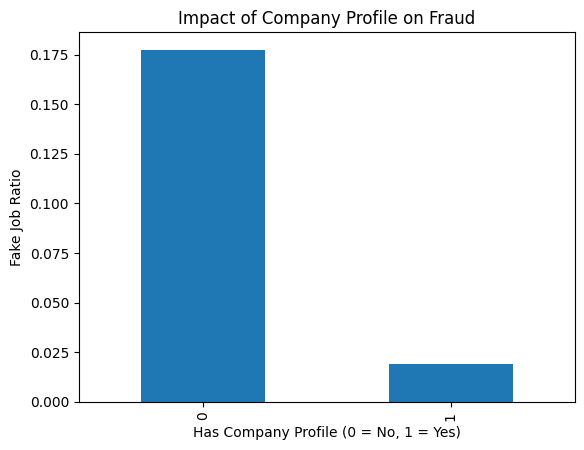

In [ ]:
data["has_company"] = (
    data["company_profile"] != ""
).astype(int)

fraud = (data.groupby("has_company")["fraudulent"].mean())

fraud.plot(kind="bar")
plt.xlabel("Has Company Profile (0 = No, 1 = Yes)")
plt.ylabel("Fake Job Ratio")
plt.title("Impact of Company Profile on Fraud")
plt.show()

In [ ]:
data.groupby("department")["employment_type"].sum()

,employment_type
department,
,Full-timeFull-timePart-timeFull-timeFull-timeF...
,Part-timeFull-timePart-timePart-timeFull-timeP...
\tCorporate Shared Services,Full-time
Lower Level Management,
Marketing,Full-time
...,...
warehouse,Full-timeFull-timeFull-time
web development,
Área Comercial,


In [ ]:
data.groupby(["benefits","required_experience"]).agg({"industry":"sum"}).sort_values(by="industry",ascending=False)

,,industry
benefits,required_experience,
"All students and recent graduates hired will receive substantial payments for each projects completed. Additionally, by completing each project you'll be able to be interviewed by great tech companies like Facebook, Google, Microsoft, Oracle, Salesforce and more!",Internship,Writing and EditingWriting and Editing
"Ample paid time off (a.k.a. PTO) so you can finally take that vacation when required.All the usual company holidays, plus a few you might not expect.A sweet 401k plan with company matching (retirement, here you come!)Flexible work arrangements to accommodate your ever-busier life.Enough free snacks and drinks on overtimes to make your dentist nervous.An annual company outing that people actually want to attend.Legitimately great medical and dental coverage with low premiums and co-pays (Coming Soon)A work environment that's so fun and casual we hesitate to call it &ldquo;work&rdquo;.Aptitude tests so you never have to stop learning.",Associate,Writing and Editing
"Extremely competitive salary.Equity in the company (ESOPs). We believe in empowering our employees and team. Experience working with a motivated team to build a hot start up.Milestone/Performance Based Bonuses.Flexible work hours: We're not big fans of fixed working hours - you can work according to your convenience, as long as you can stay productive and deliver results.We're a small, tight knit group and are also best friends. This means regular meetups, outings and other fun stuff. Access to sessions on technology, funding, marketing from industry stalwarts.The best possible exposure to the intricate details of the startup universe. (A number of our ex-interns have already started up)Chance to work with a highly passionate and young team in a fun environment. (Company culture is very important to us)",Internship,Writing and Editing
$100 per story (5 stories total)More paid work if this project goes wellResume feedback when the project is completeOffice space at WeWork in Fort PointRegular assessments of skills utilized to increase experience seeker's marketability in the future Can work remote (virtual),Internship,Writing and Editing
"Experience working with a motivated team to build a hot start up.Milestone/Performance Based Bonuses.Get a chance to work with various clients, startups &amp; big brands.Flexible work hours: We're not big fans of fixed working hours - you can work according to your convenience, as long as you can stay productive and deliver results.We're a small, tight knit group and are also best friends. This means regular meetups, outings and other fun stuff. A stipend that won’t make you rich, but will take care of your needs.Access to sessions on technology, funding, marketing from industry stalwarts.The best possible exposure to the intricate details of startup universe.",Associate,Writing and Editing
...,...,...
"- Attractive Remuneration Package.- Work in an international, dynamic and fun atmosphere among young and smart people- Huge learning experience in using best practices and cutting-edge technologies- Challenging engineering projects in an interesting and complex travel industry.",,
"- Approximate offered salary: 250Euros- Work in an international, dynamic and fun atmosphere among young and smart people- Huge learning experience in using best practices and cutting-edge technologies- Challenging engineering projects in an interesting and complex travel industry.",,
"- Attractive Remuneration Package- Private medical insurance- Work in an international, dynamic and fun atmosphere among young and smart people- Huge learning experience in using best practices and cutting-edge technologies",,


In [ ]:
data['function'].value_counts

<bound method IndexOpsMixin.value_counts of 0                   Marketing
1            Customer Service
2                            
3                       Sales
4        Health Care Provider
                 ...         
17875                   Sales
17876     Accounting/Auditing
17877                        
17878                  Design
17879             Engineering
Name: function, Length: 17880, dtype: object>

<Axes: xlabel='function', ylabel='Count'>

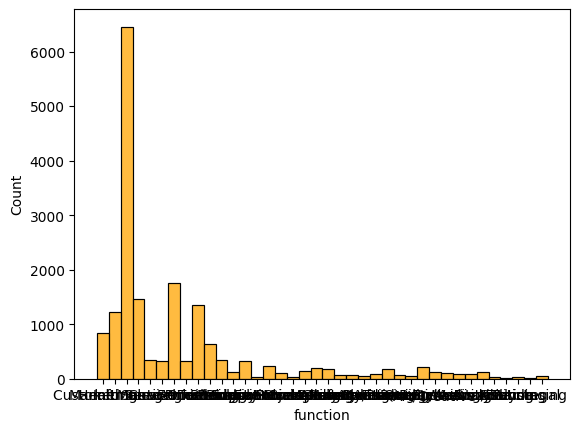

In [ ]:
sns.histplot(data["function"], color= "orange")



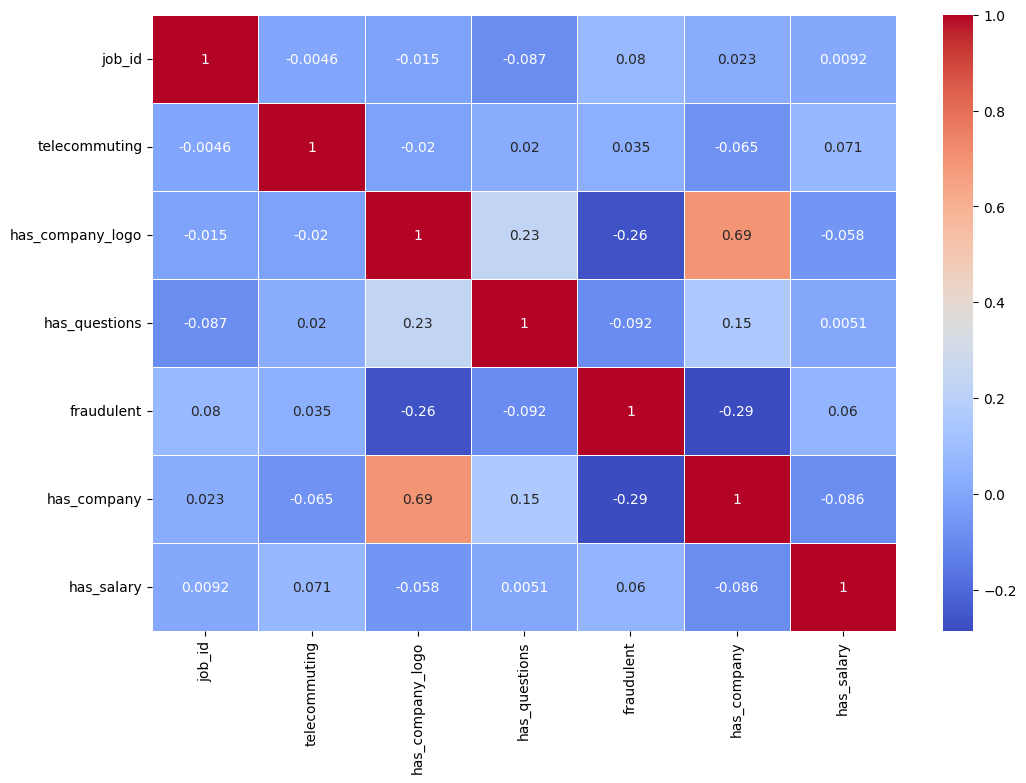

In [ ]:
f = data.select_dtypes(
    include=np.number
)

values = f.corr()

plt.figure(figsize=(12,8))

sns.heatmap(values,cmap="coolwarm",annot=True,linewidths=0.7)



plt.show()

In [ ]:
txt = data["text"]
fraud = data["fraudulent"]
txt, fraud

(0        marketing intern food52  a fast growing  james...
 1        customer service   cloud video production orga...
 2        commissioning machinery assistant  cma  our cl...
 3        account executive   washington dc the company ...
 4        bill review manager job title  itemization rev...
                                ...                        
 17875    account director   distribution  just in case ...
 17876    payroll accountant the payroll accountant will...
 17877    project cost control staff engineer   cost con...
 17878    graphic designer nemsia studios is looking for...
 17879    web application developers who are we vend is ...
 Name: text, Length: 17880, dtype: object,
 0        0
 1        0
 2        0
 3        0
 4        0
         ..
 17875    0
 17876    0
 17877    0
 17878    0
 17879    0
 Name: fraudulent, Length: 17880, dtype: int64)

Train-Test

In [ ]:
from sklearn.model_selection import train_test_split

data_split = train_test_split(
    txt,
    fraud,
    test_size=0.2,
    random_state=40
)

train = data_split[0]
test= data_split[1]

target_train = data_split[2]
target_test = data_split[3]

print(train.shape)
print(test.shape)

print(target_train.shape)
print(target_test.shape)

(14304,)
(3576,)
(14304,)
(3576,)


TF-IDF (Feature Extraction)

In [ ]:
vec = TfidfVectorizer(
    max_features=4000,
    ngram_range=(1,2),
    stop_words='english'
)

train_vec = vec.fit_transform(train)

test_vec = vec.transform(test)

Combine Text + Metadata (Multi-Modal)

In [ ]:
vec = TfidfVectorizer(max_features=4000)
X = vec.fit_transform(data["text"])
m = data[["has_company", "has_salary"]]
X = hstack([X, m])
y = data["fraudulent"]

Logistic Regression model and accuracy

In [ ]:
logis = LogisticRegression(max_iter=1000)

logis.fit(train_vec, target_train)

y_pred_log = logis.predict(test_vec)

print("Logistic Regression:\n")
print(classification_report(target_test, y_pred_log))

logis_accuracy = accuracy_score(target_test, y_pred_log)
print(f"Logistic Accuracy: {logis_accuracy}")

Logistic Regression:

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      3404
           1       0.93      0.33      0.49       172

    accuracy                           0.97      3576
   macro avg       0.95      0.67      0.74      3576
weighted avg       0.97      0.97      0.96      3576

Logistic Accuracy: 0.9667225950782998


Random Forest and accuracy


In [ ]:
rf = RandomForestClassifier(
    n_estimators=150,
    random_state=100
)

rf.fit(train_vec, target_train)

y_pred_forest = rf.predict(test_vec)

print("Random Forest:")
print(classification_report(target_test, y_pred_forest))

rf_accuracy = accuracy_score(target_test, y_pred_forest)
print(f"Random Accuracy: {rf_accuracy}")

Random Forest:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      3404
           1       0.98      0.47      0.63       172

    accuracy                           0.97      3576
   macro avg       0.97      0.73      0.81      3576
weighted avg       0.97      0.97      0.97      3576

Random Accuracy: 0.9737136465324385


Confusion Matrix Heatmap

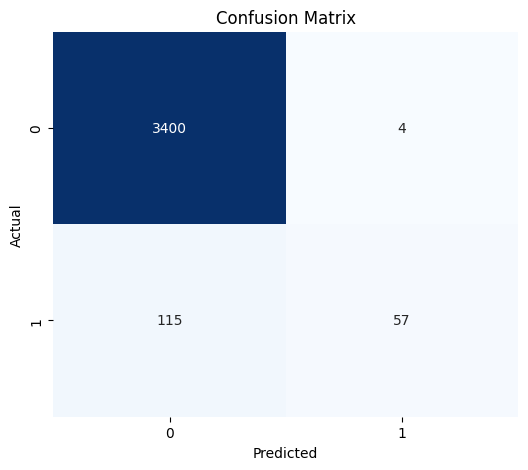

In [ ]:
def conf_matrix(true_labels, predicted_labels, title_text="Confusion Matrix"):

    matrix = confusion_matrix(true_labels, predicted_labels)

    plt.figure(figsize=(6,5))

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False
    )

    plt.title(title_text)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.show()

conf_matrix(target_test, y_pred_log, title_text="Confusion Matrix")

In [ ]:
importances = rf.feature_importances_

feature_names = vec.get_feature_names_out()

table = pd.DataFrame({
    "token": feature_names,
    "score": importances
})

features = table.sort_values(
    by="score",
    ascending=False
)

top= features.head(10)

print(top)

          token     score
922    criteria  0.013515
3929      which  0.011546
1251     enjoys  0.008365
2428         of  0.007807
3642      third  0.006701
1138     driven  0.006210
2602      peers  0.006156
1560     funnel  0.005847
615   certified  0.005369
616         cfo  0.005005


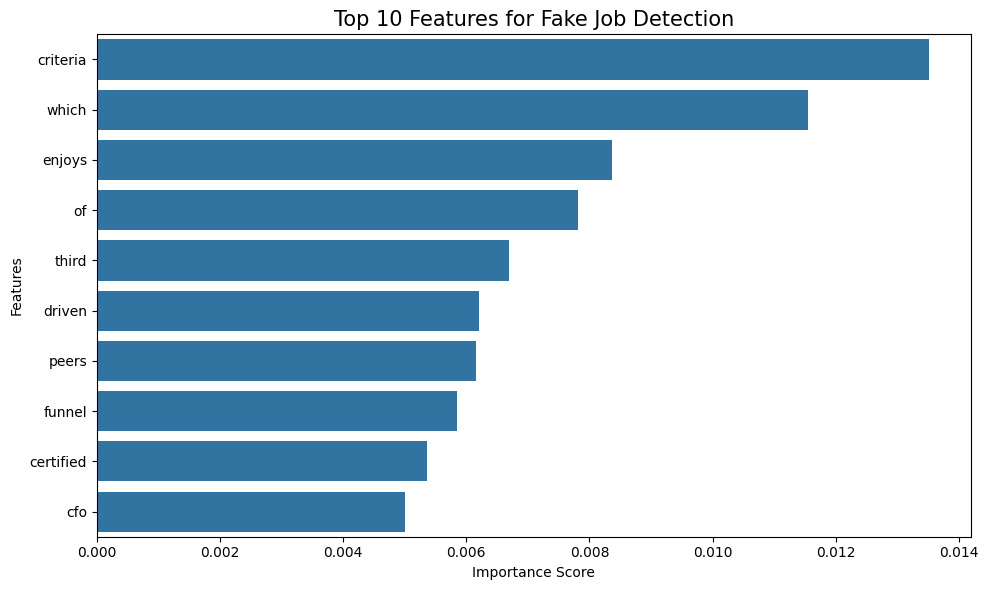

In [ ]:
vi_data = features.rename(columns={'score': 'importance', 'token': 'feature'})
top_features = vi_data.sort_values(
    "importance",
    ascending=False
).iloc[:10]

plt.figure(figsize=(10,6))

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)

plt.title("Top 10 Features for Fake Job Detection", fontsize=15)
plt.xlabel("Importance Score", fontsize=10)
plt.ylabel("Features", fontsize=10)

plt.tight_layout()
plt.show()

ROC Curve + AUC

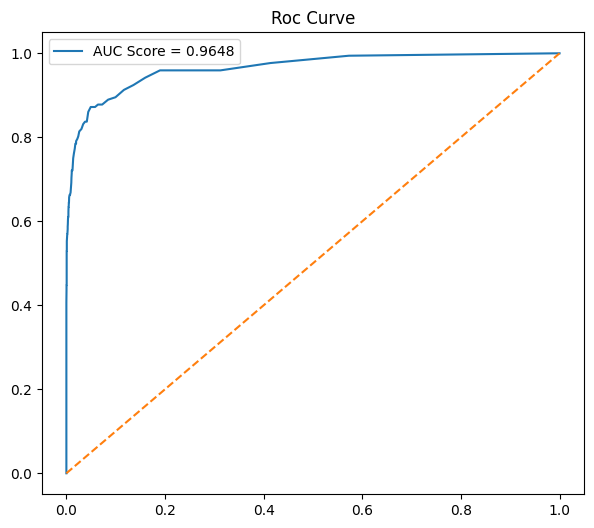

AUC value: 0.9647780996365425


In [ ]:
from sklearn.metrics import roc_curve, auc as roc_auc_func

prob = rf.predict_proba(test_vec)[:, 1]

f, t, threshold = roc_curve(target_test, prob)

roc_auc_score = roc_auc_func(f, t)

plt.figure(figsize=(7,6))

plt.plot(f, t, label=f"AUC Score = {roc_auc_score:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("Roc Curve")

plt.legend()
plt.show()

print("AUC value:", roc_auc_score)

KMeans Clustering

In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42)
clusters = kmeans.fit_predict(vec.transform(data["text"]))


data["cluster"] = clusters

pd.crosstab(data["fraudulent"], data["cluster"])


c= KMeans(
    n_clusters=2,
    random_state=42
)

label = c.fit_predict(vec.transform(data["text"]))

data["label"] = label

cluster_comparison = pd.crosstab(
    data["fraudulent"],
    data["label"]
)

cluster_comparison

label,0,1
fraudulent,,
0,726,16288
1,0,866


SVM

In [ ]:
from sklearn.svm import SVC
svm_cf = SVC(kernel="linear", probability=True)
svm_cf.fit(train_vec, target_train)
predict = svm_cf.predict(test_vec)
print("SVM Results:")
print(classification_report(target_test, predict))

SVM Results:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      3404
           1       0.94      0.45      0.61       172

    accuracy                           0.97      3576
   macro avg       0.96      0.72      0.80      3576
weighted avg       0.97      0.97      0.97      3576



Confusion Matrix (SVM)

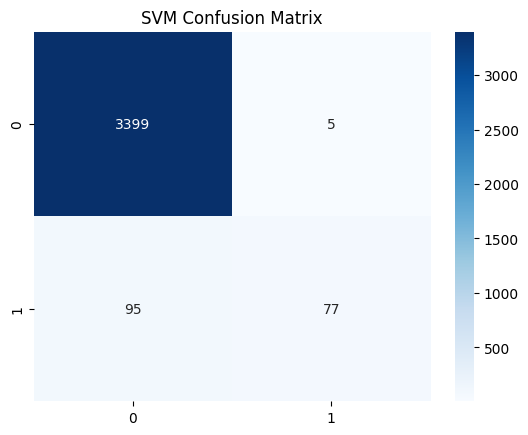

In [ ]:
sv = confusion_matrix(target_test, predict)
sns.heatmap(sv, annot=True, fmt="d", cmap="Blues")
plt.title("SVM Confusion Matrix")
plt.show()

ROC + AUC (SVM)

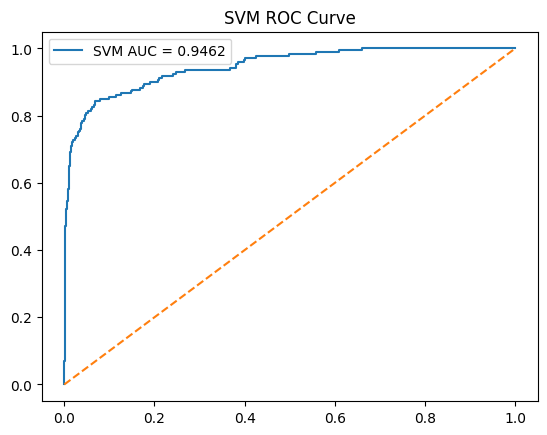

In [ ]:
from sklearn.metrics import auc
prob_s = svm_cf.predict_proba(test_vec)[:,1]
f, t, _ = roc_curve(target_test, prob_s)
roc_auc = auc(f, t)
plt.plot(f, t, label="SVM AUC = %.4f" % roc_auc)
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("SVM ROC Curve")
plt.show()

KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
# model
knn = KNeighborsClassifier(n_neighbors=5)

# train
knn.fit(train_vec, target_train)

# predict
predict_knn = knn.predict(test_vec)

# evaluation
print("KNN Results:")
print(classification_report(target_test, predict_knn))

KNN Results:
              precision    recall  f1-score   support

           0       0.98      0.99      0.98      3404
           1       0.74      0.53      0.62       172

    accuracy                           0.97      3576
   macro avg       0.86      0.76      0.80      3576
weighted avg       0.97      0.97      0.97      3576



Confusion Matrix (KNN)

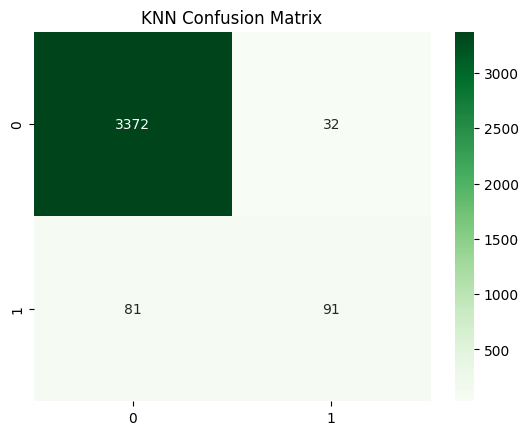

In [ ]:
knn = confusion_matrix(target_test, predict_knn)
sns.heatmap(knn, annot=True, fmt="d", cmap="Greens")
plt.title("KNN Confusion Matrix")
plt.show()

ROC + AUC (KNN)

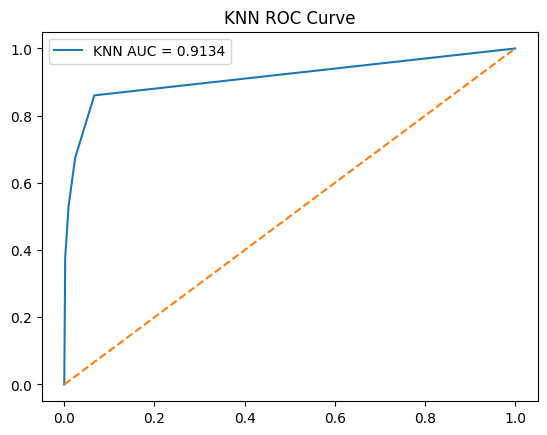

In [ ]:
from sklearn.metrics import roc_curve, auc
from sklearn.neighbors import KNeighborsClassifier
kn_cf = KNeighborsClassifier(n_neighbors=5)
kn_cf.fit(train_vec, target_train)

p_knn = kn_cf.predict_proba(test_vec)[:,1]

f, t, _ = roc_curve(target_test, p_knn)
roc_auc = auc(f, t)

plt.plot(f, t, label="KNN AUC = %.4f" % roc_auc)
plt.plot([0,1],[0,1],'--')
plt.legend()
plt.title("KNN ROC Curve")
plt.show()

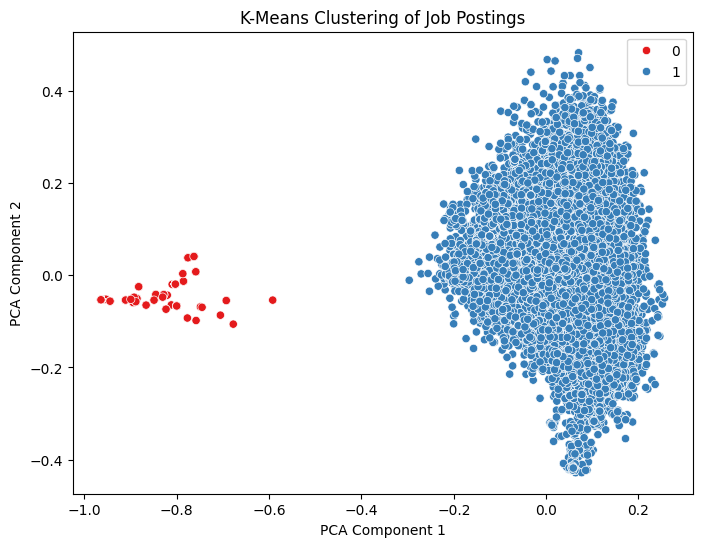

In [ ]:
# TF-IDF
t= TfidfVectorizer(max_features=1500)
x = t.fit_transform(data["text"])

# K-Means
km= KMeans(n_clusters=2, random_state=42)
clus = km.fit_predict(x)

# PCA for visualization
pc = PCA(n_components=2)
X_pca = pc.fit_transform(x.toarray())

# Plot
plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=clus, palette="Set1")

plt.title("K-Means Clustering of Job Postings")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Metadata Features

In [ ]:
def available(value):

    if value == "":
        return 0

    return 1

data["has_company"] = data["company_profile"].apply(available)

data["has_salary"] = data["salary_range"].apply(available)

RNN (LSTM)

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Concatenate, Dropout

Prepare Text Data

In [ ]:
# tokenize
t = Tokenizer(num_words=5000, oov_token="<OOV>")
t.fit_on_texts(data["text"])

# convert to sequences
seq= t.texts_to_sequences(data["text"])

# padding
x_seq= pad_sequences(seq, maxlen=130, padding='post', truncating='post')

Metadata + Target

In [ ]:
meta = data[["has_company", "has_salary"]].values
y = data["fraudulent"].values

Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X_seq_train, X_seq_test, X_meta_train, X_meta_test, y_train_dl, y_test_dl = train_test_split(
    x_seq, meta, y, test_size=0.3, random_state=130
)

Build LSTM Model

In [ ]:
# text input
input = Input(shape=(130,))
x = Embedding(input_dim=5000, output_dim=64)(input)
x = LSTM(64, return_sequences=False)(x)
x = Dropout(0.3)(x)

# metadata input
meta_inp = Input(shape=(2,))
y = Dense(8, activation='relu')(meta_inp)

# combine
combn = Concatenate()([x, y])

# final layers
fnl_lyr = Dense(32, activation='relu')(combn)
fnl_lyr = Dropout(0.3)(fnl_lyr)
outpt = Dense(1, activation='sigmoid')(fnl_lyr)

mdl = Model(inputs=[input, meta_inp], outputs=outpt)

Compile Model

In [ ]:
mdl.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

mdl.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 130)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 130, 64)   │    320,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 64)        │     33,024 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, 2)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 8)         │         24 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 72)        │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 32)        │      2,336 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32)        │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         33 │ dropout_1[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 355,417 (1.36 MB)

 Trainable params: 355,417 (1.36 MB)

 Non-trainable params: 0 (0.00 B)

Train Model

In [ ]:
hist = mdl.fit(
    [X_seq_train, X_meta_train],
    y_train_dl,
    epochs=3,
    batch_size=32,
    validation_split=0.11
)

Epoch 1/3
349/349 ━━━━━━━━━━━━━━━━━━━━ 59s 146ms/step - accuracy: 0.9518 - loss: 0.1992 - val_accuracy: 0.9579 - val_loss: 0.1514
Epoch 2/3
349/349 ━━━━━━━━━━━━━━━━━━━━ 64s 94ms/step - accuracy: 0.9630 - loss: 0.1272 - val_accuracy: 0.9651 - val_loss: 0.1278
Epoch 3/3
349/349 ━━━━━━━━━━━━━━━━━━━━ 32s 91ms/step - accuracy: 0.9716 - loss: 0.0894 - val_accuracy: 0.9666 - val_loss: 0.1355


Training Loss Graph

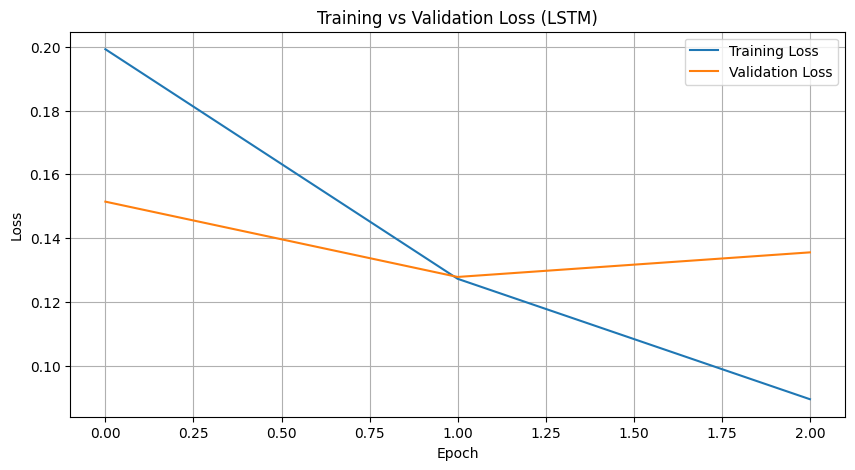

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(hist.history['loss'], label='Training Loss')
plt.plot(hist.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss (LSTM)")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

Accuracy Graph

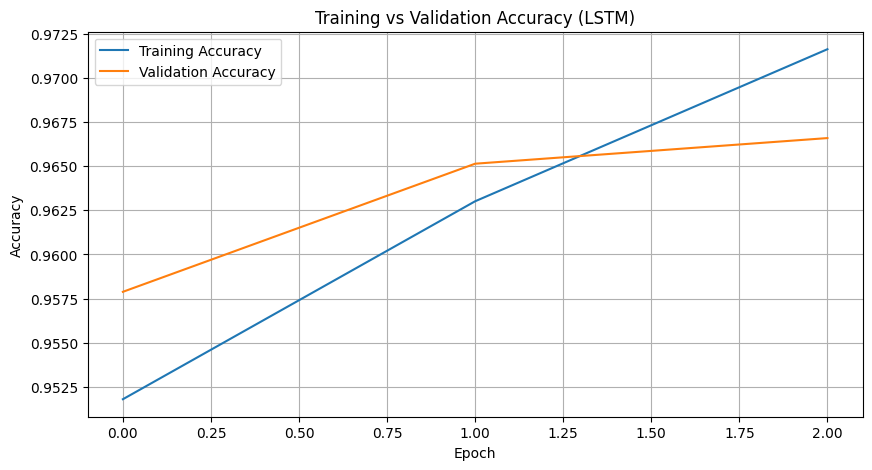

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(hist.history['accuracy'], label='Training Accuracy')
plt.plot(hist.history['val_accuracy'], label='Validation Accuracy')

plt.title("Training vs Validation Accuracy (LSTM)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)
plt.show()

Evaluate Model

In [ ]:
loss, accurate = mdl.evaluate([X_seq_test, X_meta_test], y_test_dl)
print("Test Accuracy:", accurate)

168/168 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9635 - loss: 0.1437
Test Accuracy: 0.9634600877761841


Predictions

In [ ]:
y_pred = mdl.predict([X_seq_test, X_meta_test])
y_pred = (y_pred > 0.7).astype(int)
print("predictions:", y_pred)

168/168 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step
predictions: [[0]
 [0]
 [0]
 ...
 [0]
 [0]
 [0]]


Classification Report

In [ ]:
print(classification_report(y_test_dl, y_pred))

              precision    recall  f1-score   support

           0       0.96      1.00      0.98      5097
           1       0.93      0.29      0.44       267

    accuracy                           0.96      5364
   macro avg       0.95      0.65      0.71      5364
weighted avg       0.96      0.96      0.95      5364



Confusion Matrix (LSTM)

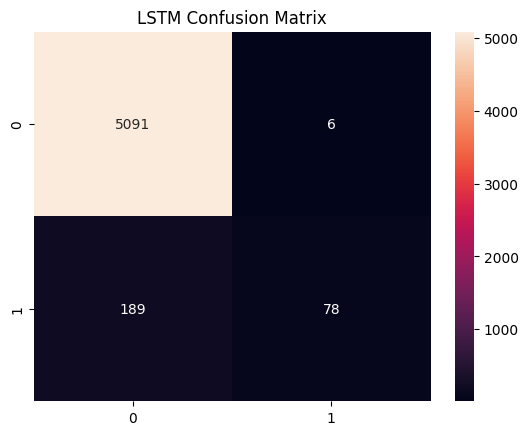

In [ ]:
conf = confusion_matrix(y_test_dl, y_pred)
sns.heatmap(conf, annot=True, fmt="d")
plt.title("LSTM Confusion Matrix")
plt.show()